Calculate how transitions between recalled items depend on their separation in the study list. Count observed transitions relative to available opportunities, compare selections and save lag-CRP curves.

## Settings

`data_paths` and `data_labels` select saved responses to compare. An explicit `data_path`
uses the existing single-input mode. Set the condition queries and analysis controls below.
See the [overview](../templates.qmd#from-a-template-to-a-run) for input files, parameter injection and independent jobs.


In [1]:
#| code-summary: "1 — Set the parameters for this run"


# Response files
data_path = None  # A supplied single path takes precedence over data_paths.
data_paths = [
    "data/Dupertuys2026.h5",
    "data/simulations/Dupertuys2026_CMR_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_source_only_demo_best_of_3.h5",
    "data/simulations/Dupertuys2026_eCMR_broad_demo_best_of_3.h5",
]
data_labels = ["Observed", "CMR", "Source-only eCMR", "Broader eCMR"]

# Saved results
output_dir = "results/crp"


# Analysis and uncertainty settings
confidence_level = 0.95
max_lag = 5
plot_seed = 0  # NumPy seed for bootstrap displays.

max_subjects = 0
figure_dir = None
figure_str = "crp"  # Empty displays the figure without saving it.


# Condition selection
trial_query = None  # When supplied, use this one selection instead of trial_queries.
trial_queries = [
    "jnp.equal(data['list_type'], 1)",
    "jnp.equal(data['list_type'], 2)",
    "jnp.equal(data['list_type'], 3)",
]
labels = ["Mixed", "Pure emotional", "Pure neutral"]
selection_label = "Selected lists"
contrast_name = None  # Legend title for the selected comparisons.
complete_lists_only = True


# Figure appearance
color_cycle = None
ylim = None
yticks = None


# Repeated-item capacity
size = 3  # Maximum study positions occupied by one item.


In [2]:
#| code-summary: "2 — Prepare the Colab environment"

import sys

if "google.colab" in sys.modules:
    import subprocess

    revision = "d919f1ad6aeacc7a36c40b96e365316219a7f40a"
    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            f"jaxcmr[colab] @ git+https://github.com/githubpsyche/jaxcmr.git@{revision}",
        ]
    )
    from jaxcmr.colab import fetch_inputs

    fetch_inputs(
        ([data_path] if data_path is not None else data_paths), revision=revision
    )


In [3]:
#| code-summary: "3 — Import packages"

from pathlib import Path

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate

from jaxcmr.analyses.crp import plot_crp
from jaxcmr.helpers import generate_trial_mask, load_data, save_figure


## Select the observations

`recalls` contains one-based study-position codes; zero marks unused response slots.
`pres_itemnos` gives within-list item codes; zero marks a padded study slot. The arrays
must retain those meanings when you substitute another dataset. SPC, PNR and lag-CRP
also use `listLength` to label their positions.

The queries choose the observations. `complete_lists_only` additionally excludes lists
with padded study slots. The printed counts report the resulting selections. Each curve first
summarizes a participant's selected lists; participants then receive equal weight.

In [4]:
#| code-summary: "4 — Resolve input paths, conditions and output settings"

np.random.seed(plot_seed)
output_dir = Path(output_dir)
figure_dir = Path(figure_dir) if figure_dir is not None else output_dir

queries = trial_queries if trial_query is None else [trial_query]
condition_labels = labels if trial_query is None else [selection_label]
input_paths = [data_path] if data_path is not None else data_paths
input_labels = [selection_label] if data_path is not None else data_labels
if len(queries) != len(condition_labels) or len(input_paths) != len(input_labels):
    raise ValueError("Supply a label for each input and each condition query.")


In [5]:
#| code-summary: "5 — Load the supplied response datasets"

datasets = [load_data(str(path), max_subjects=max_subjects) for path in input_paths]


In [6]:
#| code-summary: "6 — Select observations and report participant counts"

masks_by_dataset = []
for dataset, dataset_label in zip(datasets, input_labels):
    condition_masks = [generate_trial_mask(dataset, query) for query in queries]
    if complete_lists_only:
        condition_masks = [
            condition_mask & jnp.all(dataset["pres_itemnos"] > 0, axis=1)
            for condition_mask in condition_masks
        ]
    masks_by_dataset.append(condition_masks)
    for condition_label, condition_mask in zip(condition_labels, condition_masks):
        participant_ids = np.unique(
            np.asarray(dataset["subject"]).ravel()[np.asarray(condition_mask)]
        )
        print(
            f"{dataset_label} / {condition_label}: {int(condition_mask.sum())} lists, {len(participant_ids)} participants"
        )
        if not len(participant_ids):
            raise ValueError(
                "The selected input and condition contain no eligible lists."
            )
data, trial_masks = datasets[0], masks_by_dataset[0]


Observed / Mixed: 246 lists, 123 participants
Observed / Pure emotional: 122 lists, 122 participants
Observed / Pure neutral: 123 lists, 123 participants
CMR / Mixed: 2460 lists, 123 participants
CMR / Pure emotional: 1220 lists, 122 participants
CMR / Pure neutral: 1230 lists, 123 participants
Source-only eCMR / Mixed: 2460 lists, 123 participants
Source-only eCMR / Pure emotional: 1220 lists, 122 participants
Source-only eCMR / Pure neutral: 1230 lists, 123 participants
Broader eCMR / Mixed: 2460 lists, 123 participants
Broader eCMR / Pure emotional: 1220 lists, 122 participants
Broader eCMR / Pure neutral: 1230 lists, 123 participants


In [7]:
#| code-summary: "7 — Require complete study lists for temporal analysis"

presentations = np.asarray(data["pres_itemnos"])

for dataset, masks in zip(datasets, masks_by_dataset):
    if any(
        bool(jnp.any(mask & jnp.any(dataset["pres_itemnos"] == 0, axis=1)))
        for mask in masks
    ):
        raise ValueError("This temporal procedure requires complete study lists.")


## Follow one transition

A positive lag moves forward in the study list; a negative lag moves backward. Before the second
response, the first recalled position is no longer available. Later transitions also exclude
items already recalled. This table shows the alternatives for one actual transition.

This small illustration uses an unrepeated list. The full calculation handles repeated presentations using `size`.


In [8]:
#| code-summary: "8 — Count the choices available for one transition"

selected = np.logical_or.reduce([np.asarray(mask) for mask in trial_masks])
eligible = selected & ((np.asarray(data["recalls"]) > 0).sum(axis=1) >= 2)
unrepeated = np.array(
    [
        len(np.unique(items[items > 0])) == np.count_nonzero(items)
        for items in presentations
    ]
)
eligible_rows = np.flatnonzero(eligible & unrepeated)
if not len(eligible_rows):
    print(
        "No unrepeated list with two recalls to illustrate; transition-based summaries are undefined for this selection."
    )
else:
    row = int(eligible_rows[0])
    recall = np.asarray(data["recalls"])[row].astype(int)
    recall = recall[recall > 0]
    previous, chosen = recall[:2]
    available = np.flatnonzero(presentations[row] > 0) + 1
    available = available[available != previous]
    print(
        tabulate(
            {
                "Available study position": available,
                "Lag from previous recall": available - previous,
                "Chosen next": available == chosen,
            },
            headers="keys",
            floatfmt=".4g",
        )
    )
    print(f"Observed transition: {previous} to {chosen}; lag = {chosen - previous:+d}")


  Available study position    Lag from previous recall    Chosen next
--------------------------  --------------------------  -------------
                         1                          -1              0
                         3                           1              0
                         4                           2              0
                         5                           3              0
                         6                           4              0
                         7                           5              0
                         8                           6              1
                         9                           7              0
                        10                           8              0
                        11                           9              0
                        12                          10              0
Observed transition: 2 to 8; lag = +6


## Aggregate the eligible transitions

For each lag, divide the number of observed transitions by the number of opportunities for that
lag. This is not a histogram divided by the total number of transitions. A lag with no eligible
opportunities is undefined; zero lag is not a transition between different items.

In [9]:
#| code-summary: "9 — Prepare the condition and dataset comparison panels"

panels = []
if data_path is not None:
    panels.append(
        {
            "datasets": [data] * len(queries),
            "trial_masks": trial_masks,
            "labels": condition_labels,
            "title": selection_label,
        }
    )
else:
    for condition_index, condition_label in enumerate(condition_labels):
        panels.append(
            {
                "datasets": datasets,
                "trial_masks": [masks[condition_index] for masks in masks_by_dataset],
                "labels": input_labels,
                "title": condition_label,
            }
        )


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


... (2 outputs left out)

/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


/Users/jordangunn/Codex/2026-11-09/oka/work/vendor-simple-pytree/venv/lib/python3.12/site-packages/scipy/_lib/_util.py:306: DegenerateDataWarning: The BCa confidence interval cannot be calculated. This problem is known to occur when the distribution is degenerate or the statistic is np.min.
  return fun(*args, **kwargs)


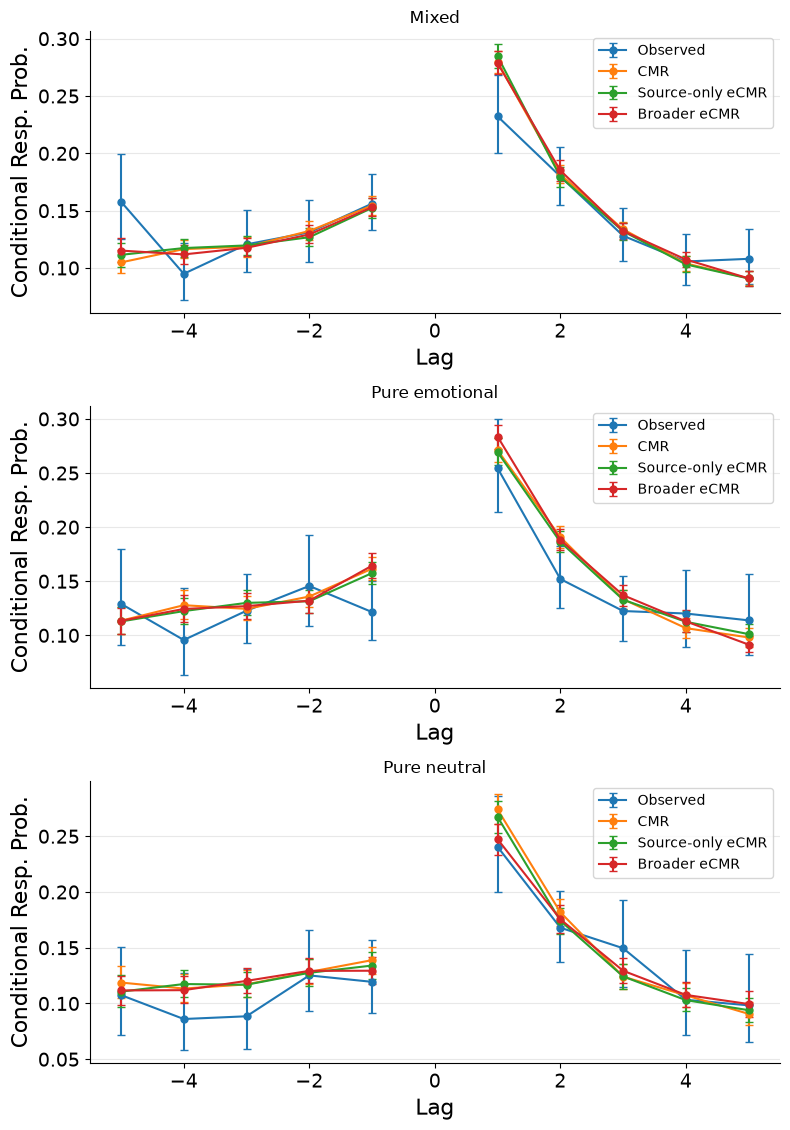

In [10]:
#| code-summary: "10 — Calculate, plot and save the selected comparison"

fig, axes = plt.subplots(len(panels), 1, figsize=(8, 3.8 * len(panels)), squeeze=False)
for ax, panel in zip(axes.ravel(), panels):
    panel_data = panel["datasets"]
    panel_masks = panel["trial_masks"]
    curve_labels = panel["labels"]
    title = panel["title"]
    plot_crp(
        panel_data,
        panel_masks,
        size=size,
        max_lag=max_lag,
        labels=curve_labels,
        contrast_name=contrast_name,
        color_cycle=color_cycle,
        confidence_level=confidence_level,
        axis=ax,
    )
    ax.set_title(title)

    if ax.get_legend_handles_labels()[1]:
        ax.legend(title=contrast_name)
    if ylim is not None:
        ax.set_ylim(ylim)
    if yticks is not None:
        ax.set_yticks(yticks)
save_figure(str(figure_dir), figure_str)


## Interpret and adapt

Peaks near zero describe temporal contiguity; an asymmetry describes a directional preference. Compare curves using the same lag range and eligibility rules. Undefined bins have no available transitions and should not be read as zero probabilities.

